# Red Agent, Part 1 - DCGAN evaluation (25 vs 50 epochs)

measures how good the DCGAN's synthetic faces are, compares the **25-epoch** and **50-epoch** generators, and saves figures + numbers for the report. nothing is trained here.

**needs (inside `celeba/` on the pod):** `generator_dcgan_25ep.pth`, `generator_dcgan_50ep.pth`, `dcgan_checkpoint_50ep.pth`, `preprocessed_v2/`, `train_split.csv`

**outputs:** `celeba/dcgan_eval/` (figures + `metrics.csv`) and `celeba/dcgan_eval.zip` for download.

| metric | what it means | better |
|---|---|---|
| **FID** (Fréchet Inception Distance) | how close the *distribution* of fake faces is to real faces, measured with an Inception network. the standard GAN quality number | **lower** |
| **face detected (MTCNN ≥ 0.90)** | % of fakes that our own preprocessing detector (same MTCNN + same 0.90 threshold as `Dataset.ipynb`) accepts as a face | **higher** |
| **FaceNet best match** | average cosine similarity between each fake and its closest real face, using our FaceNet model - how "person-like" a fake looks to the recognizer | **higher** = more convincing |

a **real-vs-real baseline** is computed for every metric, so you can see what "perfect" looks like with the same sample sizes.

### setup

In [6]:
import os
os.chdir("/workspace")
print("working directory:", os.getcwd())

import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torchvision import transforms
from torchvision.utils import save_image, make_grid
from facenet_pytorch import InceptionResnetV1, MTCNN
from pytorch_fid.fid_score import compute_statistics_of_path
from pytorch_fid.inception import InceptionV3
from scipy import linalg

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

BASE = "./celeba"
IMG_DIR = os.path.join(BASE, "preprocessed_v2")
EVAL_DIR = os.path.join(BASE, "dcgan_eval")
os.makedirs(EVAL_DIR, exist_ok=True)

GEN_PATHS = {
    "DCGAN 25 epochs": os.path.join(BASE, "generator_dcgan_25ep.pth"),
    "DCGAN 50 epochs": os.path.join(BASE, "generator_dcgan_50ep.pth"),
}
CKPT_50 = os.path.join(BASE, "dcgan_checkpoint_50ep.pth")
for p in list(GEN_PATHS.values()) + [CKPT_50, IMG_DIR]:
    print("ok     " if os.path.exists(p) else "MISSING", p)

N_FID = 5000     # images per set for FID
N_FACE = 1000    # images per set for the MTCNN / FaceNet checks
NOISE_DIM = 100
SEED = 42
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)

working directory: /workspace
device: cuda
ok      ./celeba/generator_dcgan_25ep.pth
ok      ./celeba/generator_dcgan_50ep.pth
ok      ./celeba/dcgan_checkpoint_50ep.pth
ok      ./celeba/preprocessed_v2


### the generator
the exact class from `RedAgent_DCGAN.ipynb` (64x64), so both saved generators load into it.

In [7]:
class Generator(nn.Module):
    def __init__(self, noise_dim=100, feature_maps=64):
        super().__init__()
        self.main = nn.Sequential(
            nn.ConvTranspose2d(noise_dim, feature_maps * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(feature_maps * 8),
            nn.ReLU(True),
            nn.ConvTranspose2d(feature_maps * 8, feature_maps * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_maps * 4),
            nn.ReLU(True),
            nn.ConvTranspose2d(feature_maps * 4, feature_maps * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.ReLU(True),
            nn.ConvTranspose2d(feature_maps * 2, feature_maps, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_maps),
            nn.ReLU(True),
            nn.ConvTranspose2d(feature_maps, 3, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, x):
        return self.main(x)

generators = {}
for name, path in GEN_PATHS.items():
    g = Generator(NOISE_DIM).to(device)
    g.load_state_dict(torch.load(path, map_location=device, weights_only=True))
    generators[name] = g.eval()
    print("loaded", name)

@torch.no_grad()
def generate(g, n, batch=500):
    # n fake faces, 64x64, range [-1, 1]
    out = []
    for i in range(0, n, batch):
        z = torch.randn(min(batch, n - i), NOISE_DIM, 1, 1, device=device)
        out.append(g(z).cpu())
    return torch.cat(out)

loaded DCGAN 25 epochs
loaded DCGAN 50 epochs


### figure 1 - 25 vs 50 epochs on the same noise
same 32 random noise vectors fed to both generators, so each position shows "the same" face at 25 and at 50 epochs. also saves a clean 8x8 grid of the final generator for slides.

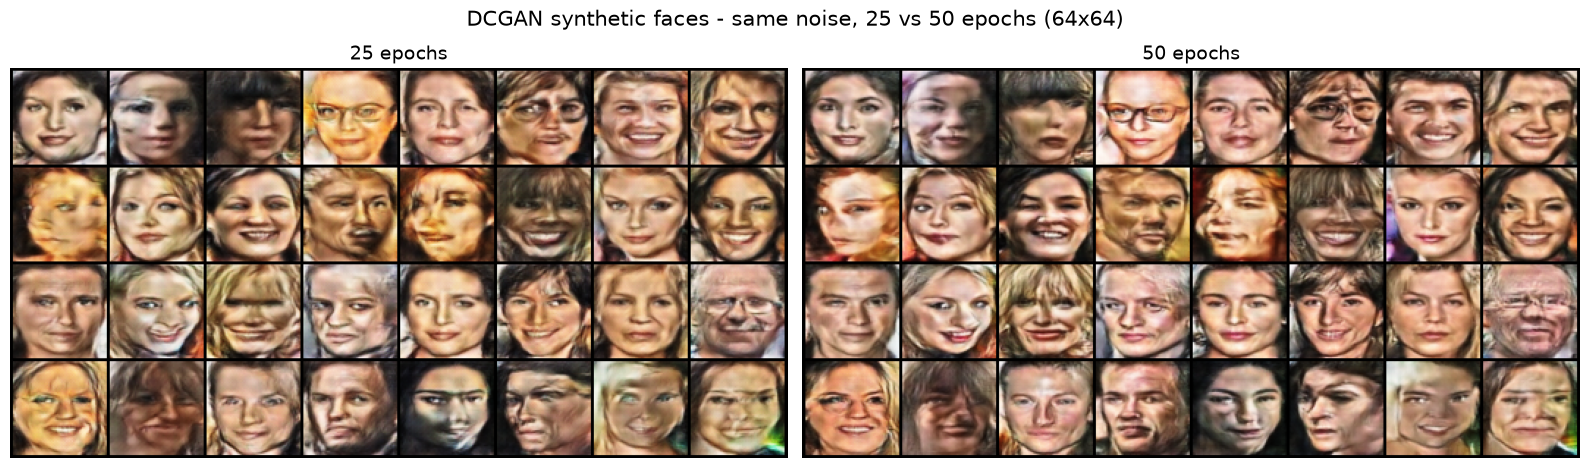

saved compare_25_vs_50.png, final_50ep_grid_64px.png, final_50ep_grid_160px.png


In [8]:
z = torch.randn(32, NOISE_DIM, 1, 1, device=device)
with torch.no_grad():
    g25 = generators["DCGAN 25 epochs"](z).cpu()
    g50 = generators["DCGAN 50 epochs"](z).cpu()

fig, axes = plt.subplots(1, 2, figsize=(16, 4.9))
for ax, imgs, title in [(axes[0], g25, "25 epochs"), (axes[1], g50, "50 epochs")]:
    ax.imshow(make_grid(imgs * 0.5 + 0.5, nrow=8, padding=2).permute(1, 2, 0).clamp(0, 1).numpy())
    ax.set_title(title, fontsize=14)
    ax.axis("off")
plt.suptitle("DCGAN synthetic faces - same noise, 25 vs 50 epochs (64x64)", fontsize=15)
plt.tight_layout()
plt.savefig(os.path.join(EVAL_DIR, "compare_25_vs_50.png"), dpi=150, bbox_inches="tight")
plt.show()

final = generate(generators["DCGAN 50 epochs"], 64)
save_image(final * 0.5 + 0.5, os.path.join(EVAL_DIR, "final_50ep_grid_64px.png"), nrow=8, padding=2)
save_image(F.interpolate(final, size=160, mode="bilinear", align_corners=False).clamp(-1, 1) * 0.5 + 0.5,
           os.path.join(EVAL_DIR, "final_50ep_grid_160px.png"), nrow=8, padding=2)
print("saved compare_25_vs_50.png, final_50ep_grid_64px.png, final_50ep_grid_160px.png")

### figure 2 - training loss over all 50 epochs
from the 50-epoch checkpoint (last batch of each epoch, as stored by the training notebook). the dashed line marks where training was resumed (after epoch 25). GAN losses always jump around - judge quality by the images and the metrics below, not by this curve.

epochs in checkpoint: 50


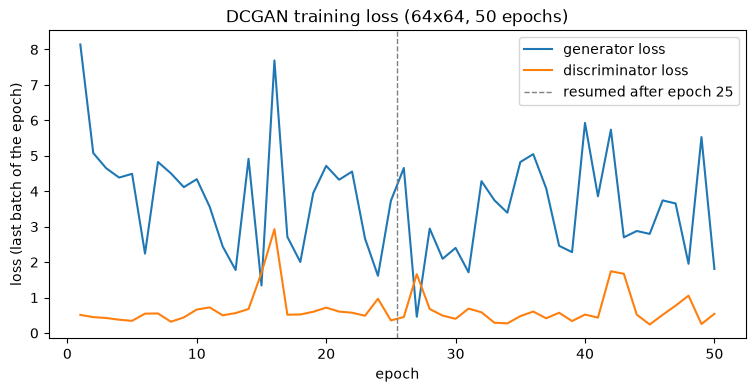

In [9]:
ckpt = torch.load(CKPT_50, map_location="cpu", weights_only=True)
g_losses, d_losses = ckpt["g_losses"], ckpt["d_losses"]
epochs = range(1, len(g_losses) + 1)
print("epochs in checkpoint:", len(g_losses))

plt.figure(figsize=(9, 4))
plt.plot(epochs, g_losses, label="generator loss")
plt.plot(epochs, d_losses, label="discriminator loss")
plt.axvline(25.5, color="gray", linestyle="--", linewidth=1, label="resumed after epoch 25")
plt.xlabel("epoch")
plt.ylabel("loss (last batch of the epoch)")
plt.title("DCGAN training loss (64x64, 50 epochs)")
plt.legend()
plt.savefig(os.path.join(EVAL_DIR, "loss_curve_50ep.png"), dpi=150, bbox_inches="tight")
plt.show()

### metric 1 - FID
writes 5,000 images per set to folders and lets `pytorch-fid` compare them. everything is compared at **64x64** (real faces are resized to 64x64 exactly like the DCGAN training data), so the GAN is not penalized for its output size.

- `real A vs real B` = two different sets of real faces -> the **best value possible** with 5,000 images (FID never reaches 0 with a finite sample).
- with 5,000 images FID values are higher than the 50,000-image numbers in papers - compare the rows **with each other**, not with published numbers.

In [10]:
train_df = pd.read_csv(os.path.join(BASE, "train_split.csv"))
files = rng.permutation(train_df["file_name"].values)
real_a, real_b = files[:N_FID], files[N_FID:2 * N_FID]
to64 = transforms.Compose([transforms.Resize(64), transforms.CenterCrop(64)])   # same resize as DCGAN training

def write_real(names, folder):
    os.makedirs(folder, exist_ok=True)
    for f in names:
        to64(Image.open(os.path.join(IMG_DIR, f)).convert("RGB")).save(os.path.join(folder, f))

def write_fake(g, n, folder):
    os.makedirs(folder, exist_ok=True)
    imgs = generate(g, n)
    for k, img in enumerate(imgs):
        save_image(img * 0.5 + 0.5, os.path.join(folder, f"fake_{k:05d}.png"))

fid_dir = os.path.join(BASE, "fid_tmp")
shutil.rmtree(fid_dir, ignore_errors=True)
write_real(real_a, os.path.join(fid_dir, "real_a"))
write_real(real_b, os.path.join(fid_dir, "real_b"))
for name, g in generators.items():
    write_fake(g, N_FID, os.path.join(fid_dir, name.replace(" ", "_")))
print("images written")

# FID = distance between the Inception-feature statistics (mean + covariance) of two image sets.
# pytorch-fid computes the statistics; the final formula is written out here because newer SciPy
# versions removed an option (sqrtm(..., disp=False)) that pytorch-fid still uses.
def frechet_distance(mu1, sigma1, mu2, sigma2, eps=1e-6):
    diff = mu1 - mu2
    covmean = linalg.sqrtm(sigma1.dot(sigma2))
    covmean = covmean[0] if isinstance(covmean, tuple) else covmean
    if not np.isfinite(covmean).all():
        offset = np.eye(sigma1.shape[0]) * eps
        covmean = linalg.sqrtm((sigma1 + offset).dot(sigma2 + offset))
        covmean = covmean[0] if isinstance(covmean, tuple) else covmean
    covmean = covmean.real if np.iscomplexobj(covmean) else covmean
    return float(diff.dot(diff) + np.trace(sigma1) + np.trace(sigma2) - 2 * np.trace(covmean))

inception = InceptionV3([InceptionV3.BLOCK_INDEX_BY_DIM[2048]]).to(device)
stats = {}
for folder in sorted(os.listdir(fid_dir)):
    stats[folder] = compute_statistics_of_path(os.path.join(fid_dir, folder), inception, 100, 2048, str(device), 8)
    print("statistics computed:", folder)

fid = {"real (A vs B baseline)": frechet_distance(*stats["real_a"], *stats["real_b"])}
for name in generators:
    fid[name] = frechet_distance(*stats["real_a"], *stats[name.replace(" ", "_")])
for k, v in fid.items():
    print(f"FID  {k:24s} {v:7.2f}")
shutil.rmtree(fid_dir, ignore_errors=True)

images written


100%|██████████| 50/50 [00:02<00:00, 17.52it/s]


statistics computed: DCGAN_25_epochs


100%|██████████| 50/50 [00:02<00:00, 17.26it/s]


statistics computed: DCGAN_50_epochs


100%|██████████| 50/50 [00:02<00:00, 17.14it/s]


statistics computed: real_a


100%|██████████| 50/50 [00:02<00:00, 17.26it/s]


statistics computed: real_b
FID  real (A vs B baseline)      4.17
FID  DCGAN 25 epochs            31.45
FID  DCGAN 50 epochs            18.72


### metric 2 + 3 - does our own pipeline see these as faces?
uses VigilantFace's own models on 1,000 images per set:
- **MTCNN** (same settings and the same 0.90 confidence threshold as `Dataset.ipynb`) - would our preprocessing accept the fake as a face?
- **FaceNet** (vggface2, the recognition model) - cosine similarity between each image and its **closest** face in a gallery of 1,000 real training faces.

fakes are upscaled 64 -> 160 exactly like `RedAgent_Attacks.ipynb` does. the real baseline uses unseen people (not in the training split) as queries, so no one is compared with themselves.

In [11]:
facenet = InceptionResnetV1(pretrained="vggface2").eval().to(device)
mtcnn = MTCNN(image_size=160, margin=20, post_process=False, device=device)

def load160(names):
    arr = [np.asarray(Image.open(os.path.join(IMG_DIR, f)).convert("RGB"), dtype=np.float32) / 255.0 for f in names]
    return (torch.from_numpy(np.stack(arr)).permute(0, 3, 1, 2) - 0.5) / 0.5      # [-1, 1], like the attack notebook

@torch.no_grad()
def embed(x, bs=128):
    return torch.cat([facenet(x[i:i + bs].to(device)).cpu() for i in range(0, len(x), bs)])   # L2-normalized

def detect_probs(x, bs=64):
    probs = []
    for i in range(0, len(x), bs):
        pil = [Image.fromarray(((img * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy() * 255).astype(np.uint8))
               for img in x[i:i + bs]]
        _, p = mtcnn.detect(pil)
        for pi in p:
            pi = np.atleast_1d(pi) if pi is not None else np.array([None])
            probs.append(float(np.nanmax(pi.astype(float))) if pi[0] is not None else 0.0)
    return np.array(probs)

train_set = set(train_df["file_name"])
unseen = rng.permutation([f for f in os.listdir(IMG_DIR) if f.endswith(".png") and f not in train_set])
gallery = load160(files[2 * N_FID: 2 * N_FID + N_FACE])          # real training faces (not used above)
gallery_emb = embed(gallery)

sets = {"real (unseen people)": load160(unseen[:N_FACE])}
for name, g in generators.items():
    sets[name] = F.interpolate(generate(g, N_FACE), size=160, mode="bilinear", align_corners=False).clamp(-1, 1)

face_rows = {}
for name, x in sets.items():
    p = detect_probs(x)
    best_sim = (embed(x) @ gallery_emb.T).max(1).values.numpy()
    face_rows[name] = {"face detected (MTCNN >= 0.90) %": 100 * (p >= 0.90).mean(),
                       "mean MTCNN probability": p.mean(),
                       "FaceNet best match to real faces": best_sim.mean()}
    print(f"{name:22s} detected {100 * (p >= 0.90).mean():5.1f}%   mean prob {p.mean():.3f}   FaceNet best match {best_sim.mean():.3f}")

real (unseen people)   detected  99.9%   mean prob 0.997   FaceNet best match 0.552
DCGAN 25 epochs        detected  97.2%   mean prob 0.978   FaceNet best match 0.524
DCGAN 50 epochs        detected  97.8%   mean prob 0.982   FaceNet best match 0.531


### summary - numbers for the report
`metrics.csv` and all figures are in `celeba/dcgan_eval/`, zipped to `celeba/dcgan_eval.zip`.

**how to read it:** the 50-epoch generator is better if its FID is **lower** and its face-detection rate and FaceNet best-match are **higher** than the 25-epoch generator. the real row shows the ceiling.

In [12]:
summary = pd.DataFrame(face_rows).T
summary.insert(0, "FID vs real (lower = better)", [fid["real (A vs B baseline)"]] + [fid[n] for n in generators])
summary = summary.round(3)
summary.to_csv(os.path.join(EVAL_DIR, "metrics.csv"))
print(summary.to_string())

zip_path = shutil.make_archive(os.path.join(BASE, "dcgan_eval"), "zip", EVAL_DIR)
print("\nsaved:", sorted(os.listdir(EVAL_DIR)))
print("zip:", zip_path)

                      FID vs real (lower = better)  face detected (MTCNN >= 0.90) %  mean MTCNN probability  FaceNet best match to real faces
real (unseen people)                         4.173                             99.9                   0.997                             0.552
DCGAN 25 epochs                             31.452                             97.2                   0.978                             0.524
DCGAN 50 epochs                             18.716                             97.8                   0.982                             0.531

saved: ['compare_25_vs_50.png', 'final_50ep_grid_160px.png', 'final_50ep_grid_64px.png', 'loss_curve_50ep.png', 'metrics.csv']
zip: /workspace/celeba/dcgan_eval.zip
